# Tutorial 05c — Generate OD flows from place attributes

Here the origin's total outflow is known, but its historical OD vector is not used. We estimate how that outflow is distributed across candidate destinations using distance, population/employment, land use, roads and POIs. This is a simplified, taxi-zone version of the Deep Gravity idea.

Unlike 05a–05b, the split is spatial: complete origin zones are held out. The test therefore asks whether relationships learned from some places generalise to unseen origins.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `05 Transportation Applications I`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [ ]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "05 Transportation Applications I"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn


In [1]:
import json,warnings,numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
warnings.filterwarnings("ignore"); np.random.seed(42)
FAMILY_COLORS={"Linear":"#4C78A8","Lasso":"#F58518","Ridge":"#B279A2","RF":"#54A24B","ANN":"#E45756"}
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold"})
od=pd.read_csv("nyc_static_od.csv.gz"); zones=pd.read_csv("nyc_zone_features.csv"); geo=json.load(open("nyc_taxi_zones.geojson"))
print("shape:",od.shape,"origins:",od.origin_id.nunique(),"destinations:",od.destination_id.nunique()); display(od.iloc[:5,:14]); display(od.groupby("split").origin_id.nunique())

shape: (4489, 51) origins: 67 destinations: 67


,origin_id,origin_Zone,origin_Borough,destination_id,destination_Zone,destination_Borough,split,flow,origin_outflow,share,distance_km,origin_longitude,origin_latitude,origin_population
0,4,Alphabet City,Manhattan,4,Alphabet City,Manhattan,train,127.0,7450.0,0.017047,0.000000,-73.976968,40.723752,16738.0
1,4,Alphabet City,Manhattan,12,Battery Park,Manhattan,train,1.0,7450.0,0.000134,3.991669,-73.976968,40.723752,16738.0
2,4,Alphabet City,Manhattan,13,Battery Park City,Manhattan,train,73.0,7450.0,0.009799,3.544130,-73.976968,40.723752,16738.0
3,4,Alphabet City,Manhattan,24,Bloomingdale,Manhattan,train,22.0,7450.0,0.002953,8.751128,-73.976968,40.723752,16738.0
4,4,Alphabet City,Manhattan,41,Central Harlem,Manhattan,train,31.0,7450.0,0.004161,9.217537,-73.976968,40.723752,16738.0


split
test          13
train         41
validation    13
Name: origin_id, dtype: int64

In [2]:
def polygons(feature):
    g=feature["geometry"]
    return g["coordinates"] if g["type"]=="MultiPolygon" else [g["coordinates"]]

def zone_map(values, title, cmap="YlGnBu", ax=None, colorbar=True):
    values=pd.Series(values)
    if ax is None: _,ax=plt.subplots(figsize=(8,7))
    norm=plt.Normalize(values.min(), values.max() if values.max()>values.min() else values.min()+1)
    for f in geo["features"]:
        zid=int(f["properties"]["LocationID"]); value=values.get(zid,np.nan)
        color="lightgrey" if pd.isna(value) else plt.colormaps[cmap](norm(value))
        for poly in polygons(f):
            ax.fill(*np.asarray(poly[0]).T,facecolor=color,edgecolor="white",linewidth=.45)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    if colorbar: plt.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=ax,shrink=.7)
    return ax

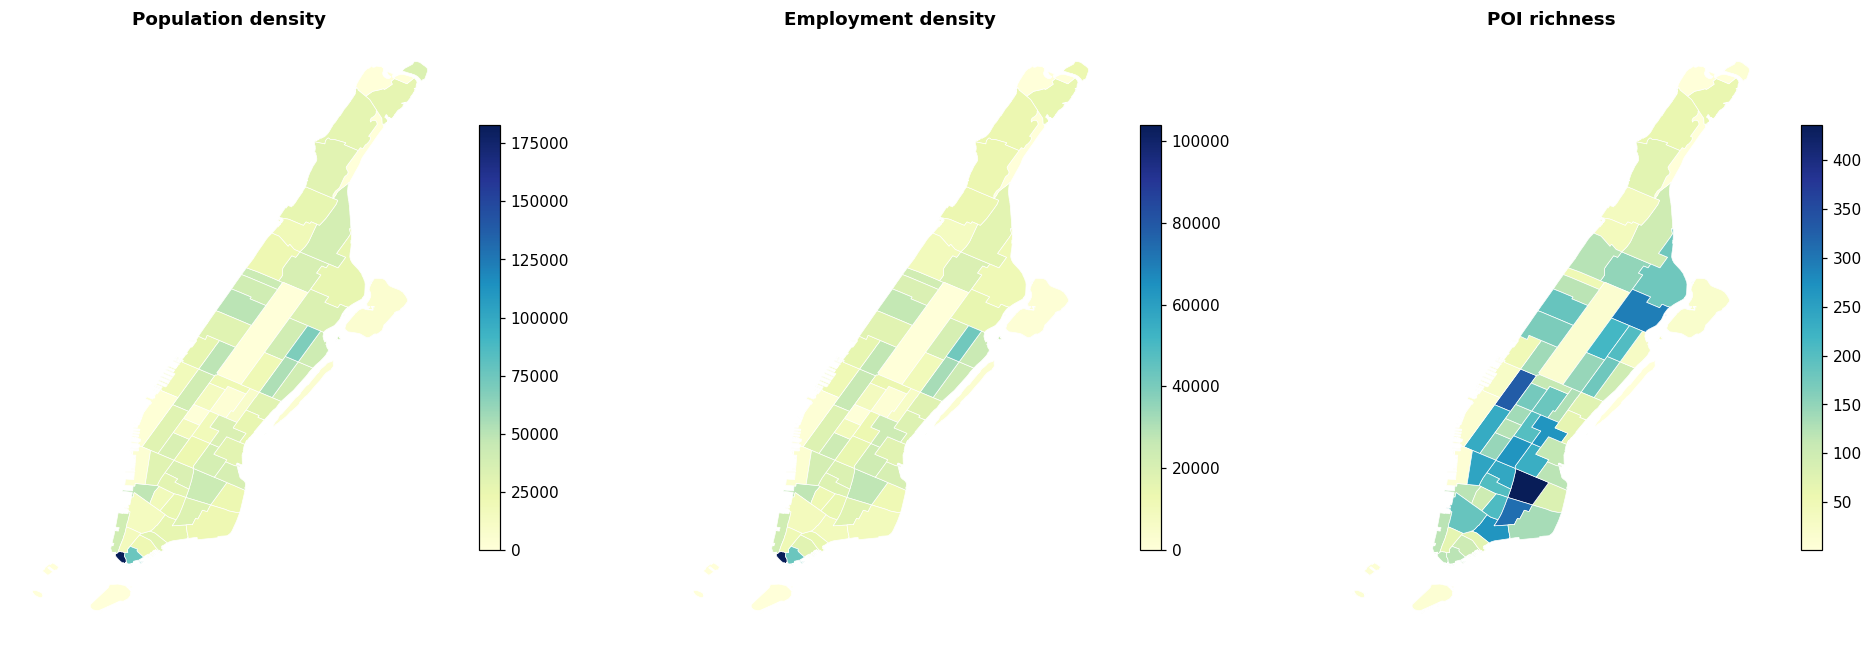

In [3]:
fig,ax=plt.subplots(1,3,figsize=(18,6)); zone_map(zones.set_index("LocationID").population_density,"Population density",ax=ax[0]); zone_map(zones.set_index("LocationID").employment_density,"Employment density",ax=ax[1]); zone_map(zones.set_index("LocationID").poi_total,"POI richness",ax=ax[2]); plt.tight_layout()

## From regression scores to a destination distribution

Each model predicts a non-negative score for every candidate destination. Scores are normalised within each origin so they sum to one, then multiplied by the known origin outflow. This separates *how much leaves an origin* from *where it goes*.

In [4]:
base=["distance_km"]
pop=base+["origin_population","destination_population","origin_employed_residents","destination_employed_residents"]
land=pop+[c for c in od if any(c.endswith(x) for x in ["commercial_landuse","industrial_landuse","natural_landuse","residential_landuse","retail_landuse","main_road","other_road","residential_road"])]
full=land+[c for c in od if any(c.endswith(x) for x in ["food_facilities","health_facilities","retail_facilities","education_facilities","transport_facilities"])]
feature_sets = {"distance": base, "+ population/employment": pop, "+ land use/roads": land, "+ POIs": full}
train = od.split.eq("train")
valid = od.split.eq("validation")
test = od.split.eq("test")
y = od.share.fillna(0).to_numpy()

X_train = od.loc[train, full].to_numpy()
y_train = y[train]
X_valid = od.loc[valid, full].to_numpy()
y_valid = y[valid]
X_test = od.loc[test, full].to_numpy()
y_test = y[test]

print("Using the complete POI feature set for this shape check:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("Each X row is one origin-destination candidate; y is its observed destination share.")
def normalise_scores(frame,scores):
    q=frame[["origin_id","origin_outflow","flow"]].copy(); q["score"]=np.clip(scores,0,None)
    total=q.groupby("origin_id").score.transform("sum"); count=q.groupby("origin_id").score.transform("size")
    q["pred_share"]=np.where(total>0,q.score/total,1/count); q["pred_flow"]=q.pred_share*q.origin_outflow
    return q
def cpc(q): return 2*np.minimum(q.flow,q.pred_flow).sum()/np.maximum((q.flow+q.pred_flow).sum(),1)
def evaluate(mask,p):
    q=normalise_scores(od.loc[mask],p); return {"MAE":mean_absolute_error(q.flow,q.pred_flow),"CPC":cpc(q)}

Using the complete POI feature set for this shape check:
X_train: (2747, 31) y_train: (2747,)
X_valid: (871, 31) y_valid: (871,)
X_test : (871, 31) y_test : (871,)
Each X row is one origin-destination candidate; y is its observed destination share.


## Validation sensitivity

Linear regression varies feature groups; the other families use the full geographic description and vary one compact hyperparameter grid. CPC measures overlap between observed and generated flows and is higher when the two OD distributions agree. Destination shares are usually only a few percent, so the ANN is trained in percentage points and converted back afterwards. This rescaling preserves the OD distribution while giving gradient-based optimisation a useful numerical signal.

In [ ]:
# StandardScaler is used only inside penalised/neural model pipelines.
# It rescales X features with different units; y, predictions, MAE, and RMSE
# remain in the original traffic-flow units shown in the result tables.
candidates={}
for label,cols in feature_sets.items(): candidates[f"Linear | {label}"]=(LinearRegression(),cols)
for a in [.001,.01,.1]: candidates[f"Lasso | alpha={a}"]=(make_pipeline(StandardScaler(),Lasso(alpha=a,max_iter=5000)),full)
for a in [.1,1,10]: candidates[f"Ridge | alpha={a}"]=(make_pipeline(StandardScaler(),Ridge(alpha=a)),full)
for depth in [4,8,None]: candidates[f"RF | depth={depth}"]=(RandomForestRegressor(n_estimators=100,max_depth=depth,min_samples_leaf=3,n_jobs=-1,random_state=42),full)
for width in [16,32]:
    ann=make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(width,16),max_iter=800,early_stopping=True,n_iter_no_change=30,tol=1e-6,random_state=42))
    candidates[f"ANN | width={width}"]=(TransformedTargetRegressor(regressor=ann,func=lambda z:z*100,inverse_func=lambda z:z/100,check_inverse=False),full)
rows=[]
for name,(m,cols) in candidates.items():
    m.fit(od.loc[train,cols],y[train]); ev=evaluate(valid,m.predict(od.loc[valid,cols])); rows.append({"family":name.split(" | ")[0],"setting":name,"validation_MAE":ev["MAE"],"validation_CPC":ev["CPC"]})
validation=pd.DataFrame(rows); best=validation.loc[validation.groupby("family").validation_CPC.idxmax()]; display(validation.sort_values(["family","validation_CPC"],ascending=[True,False])); display(best)
pv=validation.sort_values("validation_CPC"); fig,ax=plt.subplots(figsize=(9,7)); ax.barh(pv.setting,pv.validation_CPC,height=.72,color=pv.family.map(FAMILY_COLORS)); ax.set(xlabel="validation CPC",title="Validation sensitivity (higher is better)",xlim=(0,1)); ax.grid(axis="x",alpha=.18); plt.tight_layout()

## Test all frozen families once

,model,MAE,CPC
3,RF,240.488272,0.880010
0,ANN,363.072074,0.818848
4,Ridge,522.351808,0.739376
2,Linear,525.571428,0.737770
1,Lasso,587.846873,0.706698


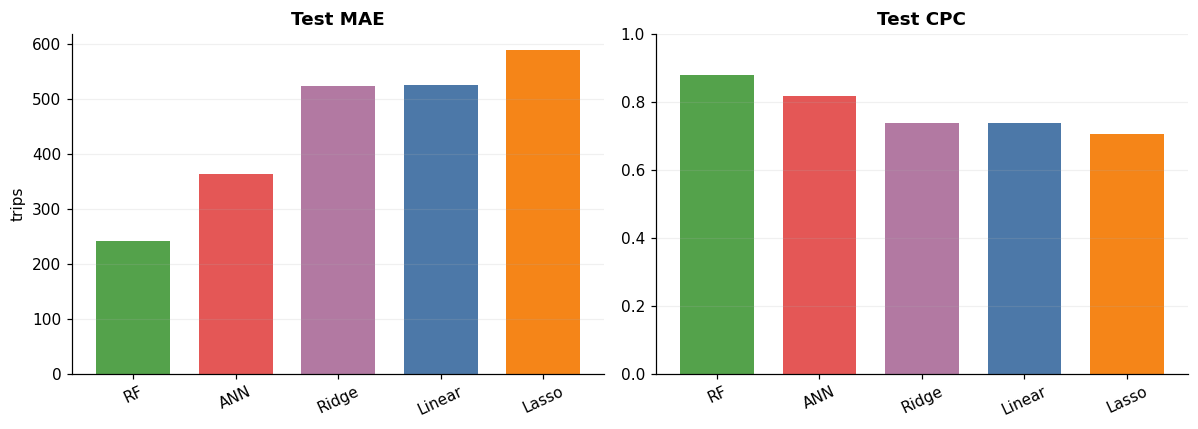

In [6]:
dev=train|valid; predictions={}; fitted={}; rows=[]
for _,r in best.iterrows():
    m,cols=candidates[r.setting]; m.fit(od.loc[dev,cols],y[dev]); q=normalise_scores(od.loc[test],m.predict(od.loc[test,cols])); predictions[r.family]=q; fitted[r.family]=(m,cols); rows.append({"model":r.family,"MAE":mean_absolute_error(q.flow,q.pred_flow),"CPC":cpc(q)})
results=pd.DataFrame(rows).sort_values("CPC",ascending=False); display(results)
fig,ax=plt.subplots(1,2,figsize=(11,4)); colors=results.model.map(FAMILY_COLORS); ax[0].bar(results.model,results.MAE,color=colors,width=.72); ax[0].set(title="Test MAE",ylabel="trips"); ax[1].bar(results.model,results.CPC,color=colors,width=.72); ax[1].set(title="Test CPC",ylim=(0,1)); [a.tick_params(axis="x",rotation=25) for a in ax]; [a.grid(axis="y",alpha=.18) for a in ax]; plt.tight_layout()

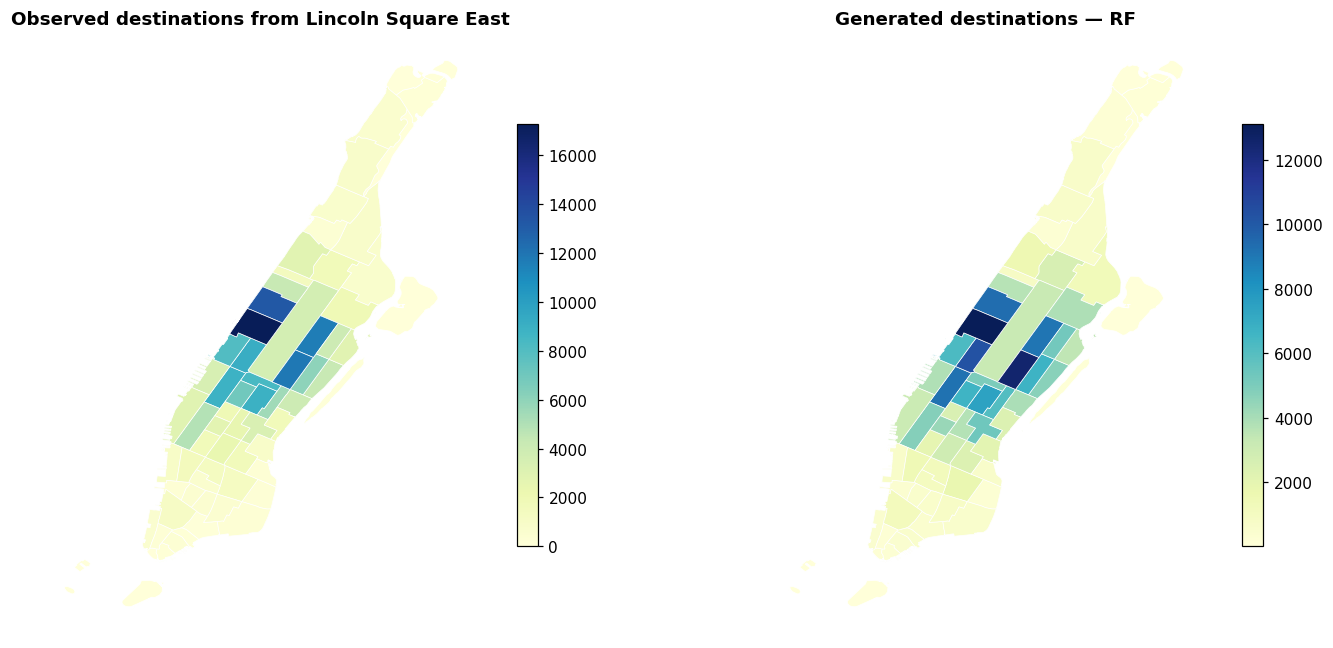

In [7]:
winner=results.iloc[0].model; q=predictions[winner].copy(); test_meta=od.loc[test,["destination_id","origin_Zone","destination_Zone"]].reset_index(drop=True); q=q.reset_index(drop=True).join(test_meta)
origin=q.groupby("origin_id").flow.sum().idxmax(); case=q[q.origin_id==origin]
fig,ax=plt.subplots(1,2,figsize=(14,6)); zone_map(case.set_index("destination_id").flow,f"Observed destinations from {case.origin_Zone.iloc[0]}",ax=ax[0]); zone_map(case.set_index("destination_id").pred_flow,f"Generated destinations — {winner}",ax=ax[1]); plt.tight_layout()

## Feature importance supports analysis, not only prediction

The forest can reveal which variables it relied on. Importance is an association inside this fitted model—not a causal statement about building POIs or moving jobs.

Inspecting named zones makes the model auditable:


,Zone,Borough,population,employed_residents,poi_total
13,East Village,Manhattan,43128.0,27487.0,436.0
8,Clinton East,Manhattan,34598.0,22723.0,329.0
33,Lower East Side,Manhattan,21247.0,11587.0,309.0
12,East Harlem South,Manhattan,52555.0,22602.0,293.0
7,Chinatown,Manhattan,18379.0,6569.0,267.0
43,Murray Hill,Manhattan,23897.0,16856.0,267.0
55,Union Sq,Manhattan,15804.0,9786.0,267.0
63,West Village,Manhattan,20876.0,14517.0,245.0


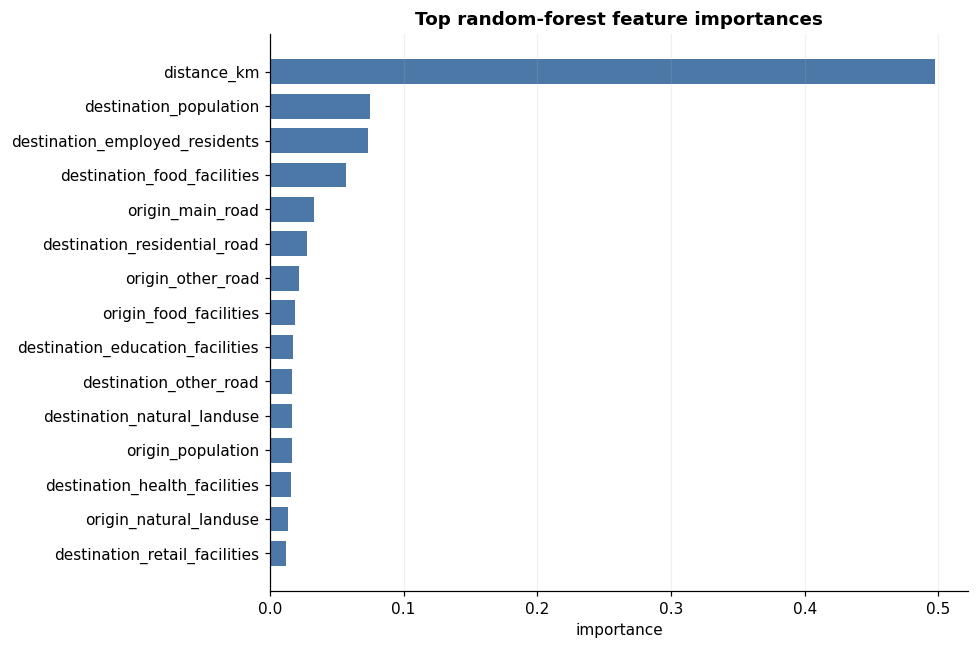

In [8]:
rf,cols=fitted["RF"]; imp=pd.Series(rf.feature_importances_,index=cols).sort_values().tail(15); fig,ax=plt.subplots(figsize=(9,6)); ax.barh(imp.index,imp.values,height=.72,color="#4C78A8"); ax.set(xlabel="importance",title="Top random-forest feature importances"); ax.grid(axis="x",alpha=.18); plt.tight_layout()
print("Inspecting named zones makes the model auditable:")
display(zones.nlargest(8,"poi_total")[["Zone","Borough","population","employed_residents","poi_total"]])